## Hawker Centre Inspection: Extension 3 (Size-Dependent and Uncertain Inspection Times)

Extension 2 assumes that every inspection takes exactly 60 minutes. Extension 3 relaxes this in two steps:

- **3A. Size-dependent inspection times.** Larger centres take longer to inspect. Inspection times are still known in advance. We run one solution, vary the time limit (as in Extension 2), then compare different values of $b$.
- **3B. Uncertain inspection times.** In real life, inspections can take longer than planned. We protect the plan against delays with budgeted robust optimisation (Lecture 5). Again we run one solution, vary the time limit, then compare different levels of protection $\alpha$.
- **3C. Simulation.** We check how often each plan from 3B would actually run over the workday.
- **3D. Sensitivity analysis.** We check whether the conclusions of 3B depend on the assumed inspection time formula.

The route, visit and MTZ constraints are the same as in Extension 2 throughout.

### Imports

In [77]:
from gurobipy import *
from itertools import combinations, permutations
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

### Load Data

In [78]:
DATA_PATH = os.path.join("..", "data", "processed")
RESULTS_PATH = os.path.join("..", "results")
os.makedirs(RESULTS_PATH, exist_ok=True)

nodes_df = pd.read_csv(os.path.join(DATA_PATH, "nodes.csv"))
travel_times_df = pd.read_csv(os.path.join(DATA_PATH, "time_matrix_min.csv"))
travel_times_df = travel_times_df.drop(columns=["from\\to"])

num_nodes = len(nodes_df)
stall_counts = nodes_df["cooked_food_stalls"].to_numpy()
short_names = nodes_df["short_name"].to_numpy()
travel_time_matrix = travel_times_df.to_numpy()
total_num_stalls = np.sum(stall_counts)

print(f"Number of nodes (including depot): {num_nodes}")
print(f"Stall counts for each node (depot's stall count is 0): {stall_counts}")
print(f"Total number of stalls: {total_num_stalls}")

Number of nodes (including depot): 8
Stall counts for each node (depot's stall count is 0): [  0  39  72  60 122  28  80  60]
Total number of stalls: 461


### Settings Used Throughout

In [79]:
TIME_LIMIT = 480        # one 8-hour workday, in minutes
EPSILON = 0.001         # tie-breaking weight on travel time (see the model below)
M = num_nodes - 1       # big-M for the MTZ constraints, as in Extension 2

---
## 3A. Size-Dependent Inspection Times

### From a fixed 60 minutes to a formula

Extension 2 uses 60 minutes for every centre. The centres in our region range from 28 to 122 cooked-food stalls, so it is more realistic for larger centres to take longer.

We keep 60 minutes as the reference point: the **median** centre has exactly 60 stalls, so a centre of median size still takes 60 minutes, as in Extension 2. Each stall above (or below) 60 adds (or removes) $b$ minutes:

$$
\bar t_i = 60 + b\,(w_i - 60),
$$

where $w_i$ is the number of cooked-food stalls at centre $i$ and $b \ge 0$ is the extra time per stall.

- $b = 0$ gives Extension 2 (60 minutes for every centre).
- $b = 1$ makes the time fully proportional to size ($\bar t_i = w_i$, i.e. 1 minute per stall).
- We use $b = 0.5$ as the baseline.

Expanding the formula with $b = 0.5$:

$$
\bar t_i = 60 + 0.5\,(w_i - 60) = 30 + 0.5\,w_i .
$$

This has a simple interpretation: a **fixed 30 minutes** per centre (arriving, meeting the manager, paperwork) plus **0.5 minutes per stall**. For example, a team of 4 officers who each need about 2 minutes per stall spends $2/4 = 0.5$ minutes per stall as a team.

In general, $\bar t_i = 60(1 - b) + b\,w_i$, so the fixed time is $60(1-b)$. We keep $0 \le b \le 1$ so that the fixed time is never negative.

In [80]:
REFERENCE_STALLS = 60   # median number of stalls; a centre of this size takes 60 minutes
REFERENCE_TIME = 60     # minutes, as in Extension 2
B_BASELINE = 0.5        # extra minutes per stall


def get_nominal_times(stall_counts, b):
    nominal_times = REFERENCE_TIME + b * (stall_counts - REFERENCE_STALLS)
    nominal_times = nominal_times.astype(float)
    nominal_times[0] = 0    # Depot (first node) has no inspection time
    return nominal_times


print(f"Median number of stalls: {np.median(stall_counts[1:]):.0f}")

nominal_times = get_nominal_times(stall_counts, B_BASELINE)
times_table = pd.DataFrame({
    "node": range(1, num_nodes),
    "centre": short_names[1:],
    "stalls": stall_counts[1:],
    "Extension 2 (b = 0)": get_nominal_times(stall_counts, 0)[1:],
    "baseline (b = 0.5)": nominal_times[1:],
    "b = 1": get_nominal_times(stall_counts, 1)[1:],
})
times_table

Median number of stalls: 60


,node,centre,stalls,Extension 2 (b = 0),baseline (b = 0.5),b = 1
0,1,Jurong West Hawker Centre,39,60.0,49.5,39.0
1,2,Boon Lay Place Market and Food Village,72,60.0,66.0,72.0
2,3,Jurong West Street 52 Blk 505,60,60.0,60.0,60.0
3,4,Taman Jurong Market and Food Centre,122,60.0,91.0,122.0
4,5,Teban Gardens Market and Food Centre,28,60.0,44.0,28.0
5,6,Ayer Rajah Food Centre,80,60.0,70.0,80.0
6,7,Clementi West Street 2 Blk 726,60,60.0,60.0,60.0


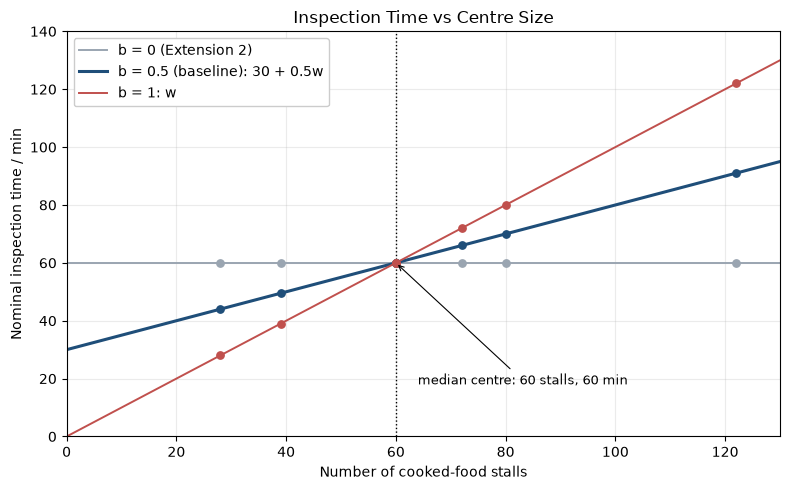

In [81]:
def plot_inspection_time_formula(file_path):
    fig, ax = plt.subplots(figsize=(8, 5))
    w = np.linspace(0, 130, 200)
    styles = {0: ("#9aa5b1", "b = 0 (Extension 2)"), 0.5: ("#1f4e79", "b = 0.5 (baseline): 30 + 0.5w"), 1: ("#c0504d", "b = 1: w")}
    for b, (color, label) in styles.items():
        ax.plot(w, REFERENCE_TIME + b * (w - REFERENCE_STALLS), color=color, linewidth=2.2 if b == B_BASELINE else 1.4, label=label)
        ax.scatter(stall_counts[1:], REFERENCE_TIME + b * (stall_counts[1:] - REFERENCE_STALLS), color=color, s=28, zorder=3)
    ax.axvline(REFERENCE_STALLS, color="black", linestyle=":", linewidth=1)
    ax.annotate("median centre: 60 stalls, 60 min", (REFERENCE_STALLS, REFERENCE_TIME), xytext=(64, 18),
                fontsize=9, arrowprops=dict(arrowstyle="->", lw=0.8))
    ax.set_title("Inspection Time vs Centre Size")
    ax.set_xlabel("Number of cooked-food stalls")
    ax.set_ylabel("Nominal inspection time / min")
    ax.set_xlim(0, 130)
    ax.set_ylim(0, 140)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=1)
    fig.tight_layout()
    plt.savefig(file_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_inspection_time_formula(os.path.join(RESULTS_PATH, "extension_3a_inspection_time_formula.png"))

### Model for 3A

The model is Extension 2 with $t_i$ replaced by $\bar t_i$:

$$
\max \quad \sum_{i=1}^{n} w_i y_i \;-\; \varepsilon \sum_{i=1}^{n}\sum_{j=1}^{n} c_{ij}x_{ij}
$$

subject to the visit, route-linking and MTZ constraints of Extension 2, and

$$
\sum_{i=1}^{n}\sum_{j=1}^{n} c_{ij}x_{ij} + \sum_{i=2}^{n} \bar t_i y_i \le T .
$$

**Tie-breaking term.** The small term $-\varepsilon \sum c_{ij}x_{ij}$ (with $\varepsilon = 0.001$) makes the solver pick the shortest route among routes that cover the same number of stalls. Stall counts are integers and total travel time is below 1000 minutes, so this term is always below 1 and never changes which centres are chosen. We also solve with `MIPGap = 0`, so that the tie-break is respected exactly.

The function below already includes the robust terms used in 3B. With $\alpha = 0$ (no protection), those terms are zero and the function solves exactly the 3A model above.

In [82]:
def run_robust_inspection(travel_times, num_nodes, stall_counts, nominal_times, deviations,
                          alpha, time_limit, M, epsilon=EPSILON, verbose=True):
    tsp = Model("Robust Selective Hawker Centre Inspection")

    # Whether we travel directly from node i to node j
    x = tsp.addVars(num_nodes, num_nodes, vtype=GRB.BINARY, name="x")

    # Whether node i is visited
    y = tsp.addVars(num_nodes, vtype=GRB.BINARY, name="y")

    # Number of nodes visited prior to arriving at node i
    u = tsp.addVars(num_nodes, name="u")

    # Dual variables of the inner (worst-case delay) problem, used in 3B
    pi = tsp.addVar(lb=0, name="pi")
    rho = tsp.addVars(range(1, num_nodes), lb=0, name="rho")

    travel = quicksum(travel_times[i, j] * x[i, j] for i in range(num_nodes) for j in range(num_nodes))

    # Objective: maximise stalls visited; break ties with the shortest route
    tsp.setObjective(
        quicksum(stall_counts[i] * y[i] for i in range(num_nodes)) - epsilon * travel,
        GRB.MAXIMIZE
    )

    # Visit constraints (same as Extension 2)
    tsp.addConstrs((x[i, i] == 0 for i in range(num_nodes)), "Cannot travel from one node to itself")
    tsp.addConstr(y[0] == 1, "Must visit depot")
    tsp.addConstrs(
        (quicksum(x[i, j] for i in range(num_nodes)) == y[j] for j in range(num_nodes)),
        "Inflow of each visited node must be 1"
    )
    tsp.addConstrs(
        (quicksum(x[i, j] for j in range(num_nodes)) == y[i] for i in range(num_nodes)),
        "Outflow of each visited node must be 1"
    )

    # Time limit: travel + nominal inspection + protection against delays (zero when alpha = 0)
    tsp.addConstr(
        travel
        + quicksum(nominal_times[i] * y[i] for i in range(num_nodes))
        + (num_nodes - 1) * alpha * pi + quicksum(rho[i] for i in range(1, num_nodes))
        <= time_limit,
        "Must be within time limit"
    )
    tsp.addConstrs(
        (pi + rho[i] >= deviations[i] * y[i] for i in range(1, num_nodes)),
        "Dual feasibility"
    )

    # Subtour-breaking constraints (same as Extension 2)
    tsp.addConstr(u[0] == 0, "Depot is the first node visited")
    tsp.addConstrs((y[i] <= u[i] for i in range(1, num_nodes)), "Lower bound for visit order")
    tsp.addConstrs((u[i] <= (num_nodes - 1) * y[i] for i in range(1, num_nodes)), "Upper bound for visit order")
    tsp.addConstrs((
        u[i] + 1 - u[j] <= M * (1 - x[i, j])
        for i in range(num_nodes)
        for j in range(1, num_nodes)
        if i != j
    ), "Subtour-breaking constraint")

    tsp.setParam("OutputFlag", verbose)
    tsp.setParam("MIPGap", 0)   # solve exactly, so the tie-breaking term is respected
    tsp.optimize()

    return tsp, x, y, u, pi, rho


def process_output(model, x, y, travel_times, nominal_times, deviations, alpha, verbose=True):
    if model.SolCount <= 0:
        if verbose:
            print(f"No feasible solution available. Solver status: {model.Status}")
        return None

    threshold = 0.5
    num_nodes = len(nominal_times)
    edges = [(i, j) for (i, j), var in x.items() if var.X > threshold]
    visited = [i for i in range(num_nodes) if y[i].X > threshold]
    centres = [i for i in visited if i != 0]

    # Follow the edges from the depot to recover the route
    route = [0]
    curr_location = 0
    for _ in range(len(visited)):
        curr_location = next(j for (i, j) in edges if i == curr_location)
        route.append(curr_location)

    travel_time = sum(travel_times[i, j] for (i, j) in edges)
    nominal_inspection = sum(nominal_times[i] for i in centres)
    # Worst-case delay in U(alpha) for the chosen centres: with budget (n - 1) * alpha,
    # the largest delays are taken in full and the next one in part
    budget = (num_nodes - 1) * alpha
    sorted_delays = sorted((deviations[i] for i in centres), reverse=True)
    k = int(np.floor(budget + 1e-9))
    protection = sum(sorted_delays[:k]) + ((budget - k) * sorted_delays[k] if k < len(sorted_delays) else 0)

    result = {
        "alpha": alpha,
        "num_centres_visited": len(centres),
        "num_stalls_visited": int(sum(stall_counts[i] for i in centres)),
        "travel_time": round(travel_time, 2),
        "nominal_time": round(travel_time + nominal_inspection, 2),
        "protected_time": round(travel_time + nominal_inspection + protection, 2),
        "route": " ".join(map(str, route)),
    }

    if verbose:
        print(f"Route: {result['route']}")
        print(f"Number of centres visited (excluding depot): {result['num_centres_visited']}")
        print(f"Number of stalls inspected: {result['num_stalls_visited']} / {total_num_stalls}")
        print(f"Travel time: {result['travel_time']} min")
        print(f"Planned time without delays: {result['nominal_time']} min")
        if alpha > 0:
            print(f"Planned time with protection (α = {alpha}): {result['protected_time']} / {TIME_LIMIT} min")
    return result

### Run 3A: One Solution (Baseline $b = 0.5$, $T = 480$, no delays)

In [83]:
no_delays = np.zeros(num_nodes)

model, x_fitted, y_fitted, _, _, _ = run_robust_inspection(
    travel_time_matrix, num_nodes, stall_counts, nominal_times, no_delays,
    alpha=0, time_limit=TIME_LIMIT, M=M, verbose=False
)
result_3a = process_output(model, x_fitted, y_fitted, travel_time_matrix, nominal_times, no_delays, alpha=0)
skipped = [f"{i} ({short_names[i]}, {stall_counts[i]} stalls)" for i in range(1, num_nodes)
           if str(i) not in result_3a["route"].split()]
print(f"Centres not visited: {skipped}")

Route: 0 2 1 3 7 6 4 0
Number of centres visited (excluding depot): 6
Number of stalls inspected: 433 / 461
Travel time: 42.87 min
Planned time without delays: 439.37 min
Centres not visited: ['5 (Teban Gardens Market and Food Centre, 28 stalls)']


### Analysis: Varying the Time Limit (Baseline $b = 0.5$)

As in Extension 2, we solve the model for every time limit from 0 to 599 minutes.

In [84]:
TIME_LIMITS = list(range(600))


def sweep_time_limits(t_bar, t_hat, alpha, time_limits):
    rows = []
    for time_limit in time_limits:
        model, x_fitted, y_fitted, _, _, _ = run_robust_inspection(
            travel_time_matrix, num_nodes, stall_counts, t_bar, t_hat,
            alpha=alpha, time_limit=time_limit, M=M, verbose=False
        )
        r = process_output(model, x_fitted, y_fitted, travel_time_matrix, t_bar, t_hat, alpha, verbose=False)
        if r is None:   # No feasible solution
            r = {"alpha": alpha, "num_centres_visited": None, "num_stalls_visited": None, "travel_time": None,
                 "nominal_time": None, "protected_time": None, "route": None}
        r["time_limit"] = time_limit
        rows.append(r)
    df = pd.DataFrame(rows)
    df[["num_centres_visited", "num_stalls_visited"]] = df[["num_centres_visited", "num_stalls_visited"]].astype("Int64")
    return df


def min_time_limit_all_stalls(df):
    all_stalls = df["num_stalls_visited"] == total_num_stalls
    return df.loc[all_stalls, "time_limit"].min() if all_stalls.any() else None


sweep_3a_baseline = sweep_time_limits(nominal_times, no_delays, alpha=0, time_limits=TIME_LIMITS)
sweep_3a_baseline.to_csv(os.path.join(RESULTS_PATH, "extension_3a_time_limits_baseline.csv"), index=False)
print(f"Smallest time limit at which all stalls can be inspected: {min_time_limit_all_stalls(sweep_3a_baseline)} min")
sweep_3a_baseline[sweep_3a_baseline["time_limit"].isin([300, 400, 480, 500])]

Smallest time limit at which all stalls can be inspected: 487 min


,alpha,num_centres_visited,num_stalls_visited,travel_time,nominal_time,protected_time,route,time_limit
300,0,4,293,23.11,289.61,289.61,0 2 1 3 4 0,300
400,0,5,394,36.15,383.15,383.15,0 2 3 7 6 4 0,400
480,0,6,433,42.87,439.37,439.37,0 2 1 3 7 6 4 0,480
500,0,7,461,46.08,486.58,486.58,0 2 1 3 5 7 6 4 0,500


In [85]:
def plot_single_vs_time_limit(df, lines, title, y_label, file_path, note, show_diagonal=False):
    # Same layout as the Extension 2 plots: shade infeasible and all-stalls ranges
    feasible = df["num_stalls_visited"].notna()
    first_feasible = df.loc[feasible, "time_limit"].min()
    first_all_stalls = min_time_limit_all_stalls(df)
    x_min, x_max = df["time_limit"].min(), df["time_limit"].max()

    fig, ax = plt.subplots(figsize=(10, 5.8))
    ax.axvspan(x_min, first_feasible - 0.5, color="#f4cccc", alpha=0.75, label="No stalls visited")
    if first_all_stalls is not None:
        ax.axvspan(first_all_stalls - 0.5, x_max, color="#d9ead3", alpha=0.75, label="All stalls visited")

    for col, color, label in lines:
        ax.plot(df.loc[feasible, "time_limit"], df.loc[feasible, col].astype(float), color=color, linewidth=1.8, label=label)

    if show_diagonal:
        ax.plot([x_min, x_max], [x_min, x_max], color="gray", linestyle="--", linewidth=1.5, label="y = x")
    ax.axvline(TIME_LIMIT, color="black", linestyle=":", linewidth=1)
    ax.text(TIME_LIMIT - 4, 0.55, f"{TIME_LIMIT} min (8-hour workday)", transform=ax.get_xaxis_transform(),
            fontsize=9, rotation=90, ha="right", va="center")

    ax.set_title(title)
    ax.set_xlabel("Allocated time limit / min")
    ax.set_ylabel(y_label)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, x_max if show_diagonal else None)
    ax.grid(True, alpha=0.25)

    # Mark the first feasible time limit and the first all-stalls time limit on the x-axis
    extra_ticks = {first_feasible} | ({first_all_stalls} if first_all_stalls is not None else set())
    base_ticks = [t for t in ax.get_xticks() if all(abs(t - e) >= 20 for e in extra_ticks)]
    ax.set_xticks(sorted(set(base_ticks) | extra_ticks))
    ax.set_xticklabels([f"{int(tick)}" for tick in ax.get_xticks()])
    ax.set_xlim(x_min, x_max)

    ax.legend(frameon=True, facecolor="white", framealpha=1, loc="lower right")
    ax.text(0.02, 0.97, note, transform=ax.transAxes, va="top",
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    fig.tight_layout()
    plt.savefig(file_path, dpi=300, bbox_inches="tight")
    plt.show()

#### Maximum Number of Stalls vs Time Limit

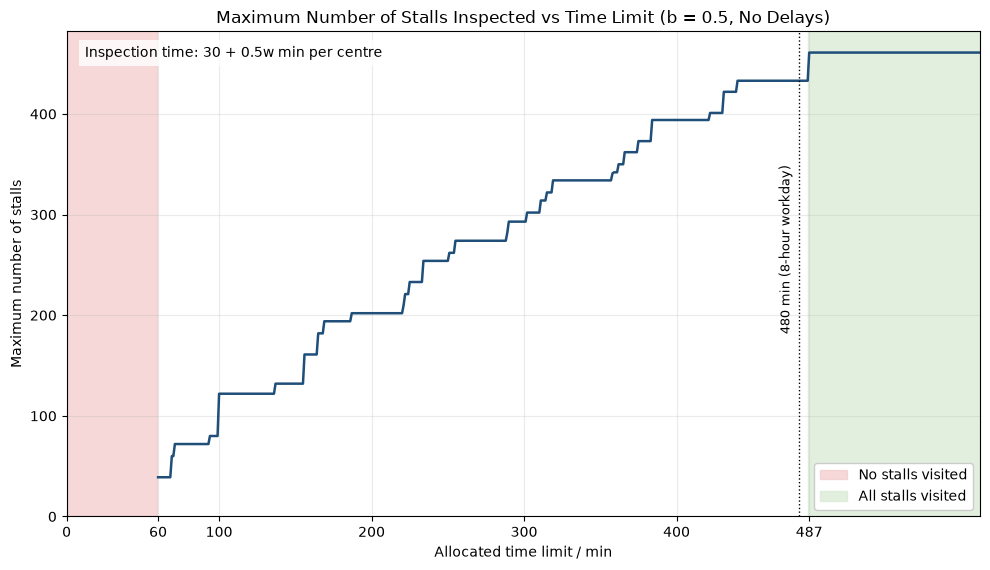

In [86]:
plot_single_vs_time_limit(
    sweep_3a_baseline, [("num_stalls_visited", "#1f4e79", None)],
    title="Maximum Number of Stalls Inspected vs Time Limit (b = 0.5, No Delays)",
    y_label="Maximum number of stalls",
    file_path=os.path.join(RESULTS_PATH, "extension_3a_num_stalls_baseline.png"),
    note="Inspection time: 30 + 0.5w min per centre",
)

#### Total Time Spent vs Time Limit

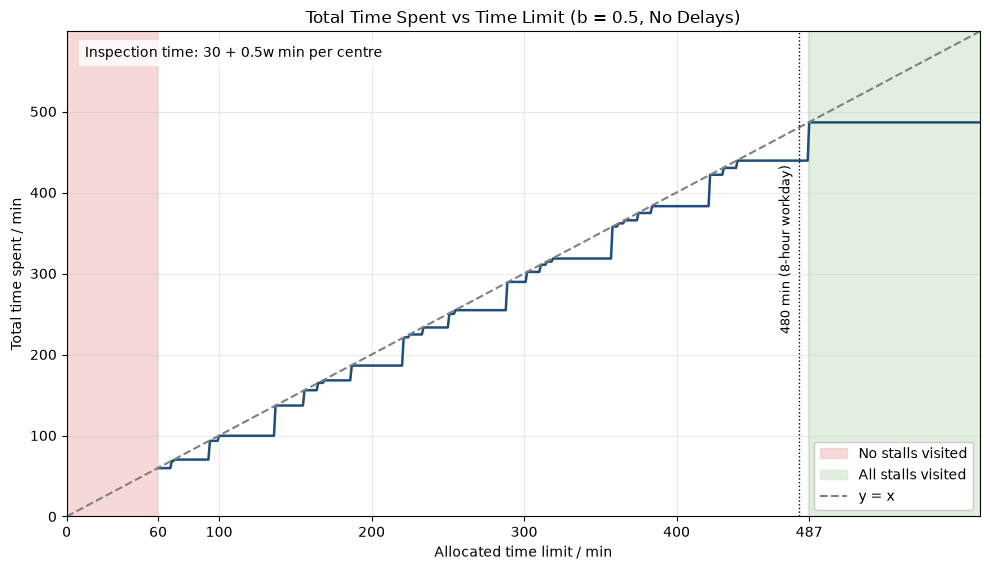

In [87]:
plot_single_vs_time_limit(
    sweep_3a_baseline, [("nominal_time", "#1f4e79", None)],
    title="Total Time Spent vs Time Limit (b = 0.5, No Delays)",
    y_label="Total time spent / min",
    file_path=os.path.join(RESULTS_PATH, "extension_3a_time_spent_baseline.png"),
    note="Inspection time: 30 + 0.5w min per centre",
    show_diagonal=True,
)

### Comparing Different Values of $b$

We now compare the baseline with $b = 0$ (60 minutes each, Extension 2) and $b = 1$ (1 minute per stall). First at the 8-hour workday, then across all time limits.

In [88]:
rows_3a = []
for b in [0, 0.5, 1]:
    t_bar = get_nominal_times(stall_counts, b)
    model, x_fitted, y_fitted, _, _, _ = run_robust_inspection(
        travel_time_matrix, num_nodes, stall_counts, t_bar, no_delays,
        alpha=0, time_limit=TIME_LIMIT, M=M, verbose=False
    )
    r = process_output(model, x_fitted, y_fitted, travel_time_matrix, t_bar, no_delays, alpha=0, verbose=False)
    r["b"] = b
    r["total_inspection_time_all_centres"] = t_bar.sum()
    rows_3a.append(r)

results_3a = pd.DataFrame(rows_3a)[["b", "total_inspection_time_all_centres", "num_centres_visited",
                                    "num_stalls_visited", "travel_time", "nominal_time", "route"]]
results_3a.to_csv(os.path.join(RESULTS_PATH, "extension_3a_results.csv"), index=False)
results_3a

,b,total_inspection_time_all_centres,num_centres_visited,num_stalls_visited,travel_time,nominal_time,route
0,0.0,420.0,7,461,46.08,466.08,0 2 1 3 5 7 6 4 0
1,0.5,440.5,6,433,42.87,439.37,0 2 1 3 7 6 4 0
2,1.0,461.0,6,433,42.87,475.87,0 2 1 3 7 6 4 0


In [89]:
sweeps_3a = []
for b in [0, 0.5, 1]:
    t_bar = get_nominal_times(stall_counts, b)
    df = sweep_time_limits(t_bar, no_delays, alpha=0, time_limits=TIME_LIMITS)
    df.insert(0, "b", b)
    sweeps_3a.append(df)
sweeps_3a = pd.concat(sweeps_3a, ignore_index=True)
sweeps_3a.to_csv(os.path.join(RESULTS_PATH, "extension_3a_time_limits.csv"), index=False)

# Smallest time limit at which all stalls can be inspected, for each b
sweeps_3a.groupby("b").apply(min_time_limit_all_stalls, include_groups=False).rename("min_time_limit_all_stalls")

b
0.0    467
0.5    487
1.0    508
Name: min_time_limit_all_stalls, dtype: int64

In [109]:
def plot_lines_vs_time_limit(df, group_col, styles, y_col, title, y_label, file_path, note,
                             show_total=False, show_diagonal=False, legend_loc="lower right"):
    fig, ax = plt.subplots(figsize=(10, 5.8))
    for value, group in df.groupby(group_col):
        color, label, width = styles[value]
        feasible = group[y_col].notna()
        ax.plot(group.loc[feasible, "time_limit"], group.loc[feasible, y_col].astype(float),
                color=color, linewidth=width, label=label, drawstyle="steps-post" if y_col == "num_stalls_visited" else "default")

    x_min, x_max = df["time_limit"].min(), df["time_limit"].max()
    if show_total:
        ax.axhline(total_num_stalls, color="gray", linestyle="--", linewidth=1.2, label=f"All stalls ({total_num_stalls})")
    if show_diagonal:
        ax.plot([x_min, x_max], [x_min, x_max], color="gray", linestyle="--", linewidth=1.2, label="y = x")
    ax.axvline(TIME_LIMIT, color="black", linestyle=":", linewidth=1)
    ax.text(TIME_LIMIT - 4, 0.55, f"{TIME_LIMIT} min (8-hour workday)", transform=ax.get_xaxis_transform(),
            fontsize=9, rotation=90, ha="right", va="center")

    ax.set_title(title)
    ax.set_xlabel("Allocated time limit / min")
    ax.set_ylabel(y_label)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, x_max if show_diagonal else total_num_stalls * 1.15)
    ax.grid(True, alpha=0.25)
    ax.legend(frameon=True, facecolor="white", framealpha=1, loc=legend_loc)
    ax.text(0.02, 0.97, note, transform=ax.transAxes, va="top",
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    fig.tight_layout()
    plt.savefig(file_path, dpi=300, bbox_inches="tight")
    plt.show()


styles_b = {
    0: ("#9aa5b1", "b = 0: 60 min each (Extension 2)", 1.4),
    0.5: ("#1f4e79", "b = 0.5: 30 + 0.5w (baseline)", 2.2),
    1: ("#c0504d", "b = 1: w", 1.4),
}

#### Maximum Number of Stalls vs Time Limit, by $b$

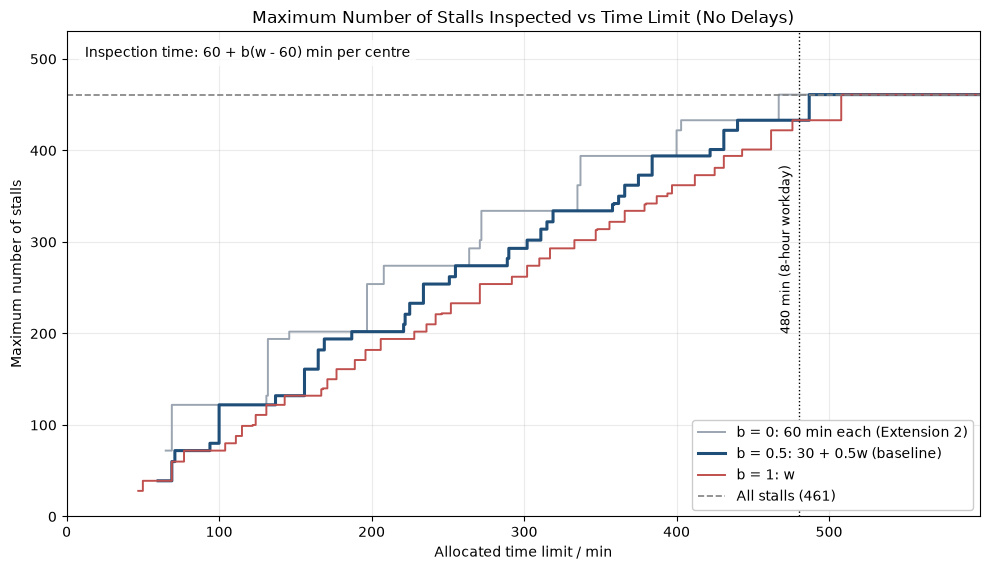

In [91]:
plot_lines_vs_time_limit(
    sweeps_3a, "b", styles_b, "num_stalls_visited",
    title="Maximum Number of Stalls Inspected vs Time Limit (No Delays)",
    y_label="Maximum number of stalls",
    file_path=os.path.join(RESULTS_PATH, "extension_3a_num_stalls_vs_time_limit.png"),
    note="Inspection time: 60 + b(w - 60) min per centre",
    show_total=True,
)

#### Total Time Spent vs Time Limit, by $b$

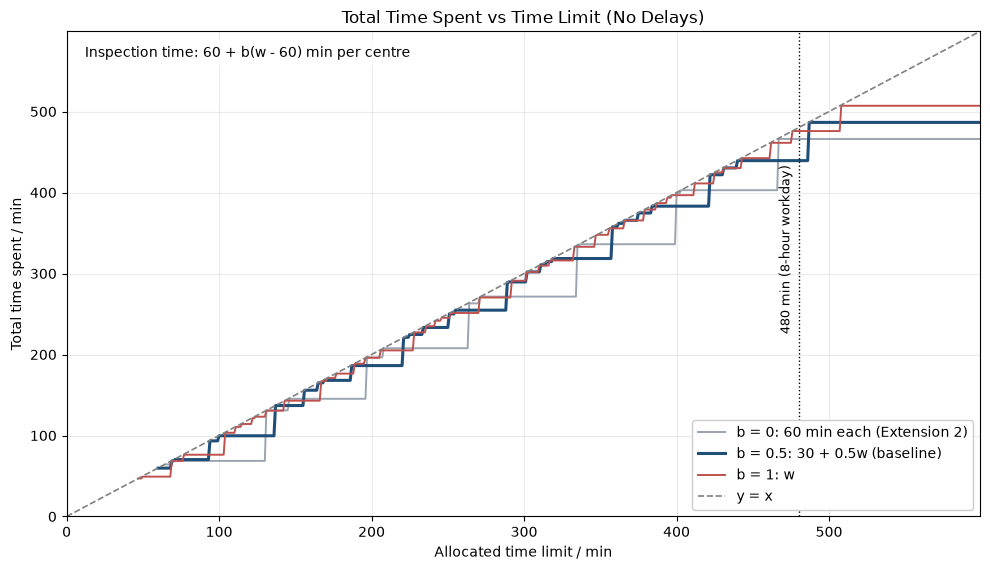

In [92]:
plot_lines_vs_time_limit(
    sweeps_3a, "b", styles_b, "nominal_time",
    title="Total Time Spent vs Time Limit (No Delays)",
    y_label="Total time spent / min",
    file_path=os.path.join(RESULTS_PATH, "extension_3a_time_spent_vs_time_limit.png"),
    note="Inspection time: 60 + b(w - 60) min per centre",
    show_diagonal=True,
)